# TP4 - Campo Magnético

**Materia:** Electricidad y Magnetismo

**Integrantes:**
* Fernanda Perez
* Tomas Aragusuku
* Jonathan Gomez
* Carla Rocca

## 1. Objetivo

El objetivo de este trabajo es:
1. Estudiar, a partir de la ley de Biot-Savart, el campo magnético que genera una espira circular sobre su eje, y cómo se combina el campo de dos espiras coaxiales según la separación entre ellas.
2. Entender por qué la configuración de **bobinas de Helmholtz** (separación igual al radio) produce una región de campo magnético prácticamente uniforme en el centro.
3. Usar esa configuración para **medir la componente horizontal del campo magnético terrestre** con una brújula, por el método de los $45°$, y comparar el resultado con el valor de referencia del modelo WMM para el lugar y la fecha de la medición.

## 2. Materiales y montaje

Para la medición se usó:

* **Dos bobinas** de $N = 200$ vueltas y radio $d = 12\,cm$, montadas coaxialmente y separadas $l = 12\,cm$ (configuración de Helmholtz).
* **Fuente de corriente continua**, para hacer circular la corriente por las bobinas.
* **Amperímetro**, conectado en serie, para medir la corriente (en la escala de mA, con lectura de dos decimales).
* **Brújula** común de laboratorio, ubicada en el centro de las bobinas.
* **Cables** para las conexiones.

El montaje consistió en conectar las dos bobinas **en serie** entre sí, de modo que la corriente circule en el mismo sentido en ambas, junto con la fuente y el amperímetro. La brújula se colocó en el centro del sistema, en el punto medio entre las dos bobinas, y el conjunto se orientó de forma que el eje de las bobinas quedara perpendicular a la aguja sin corriente (es decir, en la dirección este-oeste). El detalle del procedimiento se describe en la sección 4.

## 3. Introducción teórica

### Ley de Biot-Savart

Así como una carga en reposo genera un campo eléctrico, una carga en movimiento (una corriente $I$) genera un campo magnético $\vec{B}$. La ley de Biot-Savart da el aporte $d\vec{B}$ que genera un elemento diferencial de corriente $I\,d\vec{l}$ en un punto $P$ ubicado a una distancia $r$:

$$d\vec{B} = \frac{\mu_0}{4\pi}\,\frac{I\,d\vec{l}\times\hat{r}}{r^2}$$

donde $\mu_0$ es la permeabilidad del vacío, $d\vec{l}$ apunta en el sentido de la corriente, y $\hat{r}$ es el versor que va desde el elemento de corriente hasta $P$. El producto vectorial $d\vec{l}\times\hat{r}$ es el que define la **dirección** de $d\vec{B}$: siempre perpendicular tanto al cable como a $\hat{r}$.

### Regla de la mano derecha

Para saber el sentido de $\vec{B}$ sin calcular el producto vectorial, se usa la regla de la mano derecha: enroscando los dedos en el sentido en el que circula la corriente, el pulgar indica el sentido del campo magnético generado.

### Principio de superposición

El campo total en un punto no lo genera un único elemento de corriente, sino **todo** el circuito. Por eso el campo total es la suma (integral) de los aportes $d\vec{B}$ de cada elemento:

$$\vec{B} = \int d\vec{B} = \int \frac{\mu_0}{4\pi}\,\frac{I\,d\vec{l}\times\hat{r}}{r^2}$$

### Caso 1: cable conductor infinito

Para un cable recto e infinito, integrando la expresión anterior a lo largo de todo el cable se obtiene un resultado simple, que depende solo de la distancia $r$ al cable:

$$B = \frac{\mu_0 I}{2\pi r}$$

El campo es inversamente proporcional a $r$, y directamente proporcional a $I$.

### Caso 2: espira circular (campo sobre el eje)

Para una espira circular de radio $d$, el comportamiento es distinto. Tomamos un punto $P$ sobre el eje de la espira (perpendicular al plano de la espira, pasando por su centro), a una distancia $z$ del centro:

<p align="center">
  <img src="imagenes/campo.jpeg" width="70%">
</p>
<p align="center"><em>Geometría de la espira: el elemento $I\,d\vec{l}$ genera $d\vec{B}$ en P, con una componente $dB_y$ que se cancela por simetría y una componente axial $dB_x$ que sobrevive al integrar (acá llamada $d$ en vez de $R$, y $z$ en vez de $x$).</em></p>

Cada elemento $d\vec{l}$ de la espira está a la misma distancia $r=\sqrt{z^2+d^2}$ de $P$, y genera un $d\vec{B}$ con una componente a lo largo del eje y otra perpendicular a él. Por la simetría de la espira, las componentes perpendiculares de elementos opuestos se cancelan entre sí al sumarlas (superposición), y solo sobreviven las componentes a lo largo del eje. Integrando esas componentes sobre toda la espira:

$$\vec{B} = \frac{\mu_0 I}{2}\,\frac{d^2}{\left(z^2+d^2\right)^{3/2}}\,\hat{k}$$

con $\hat{k}$ en la dirección del eje. En el centro de la espira ($z=0$) esto se reduce a:

$$\vec{B} = \frac{\mu_0 I}{2d}\,\hat{k}$$

A diferencia del cable infinito, acá el campo **no diverge** cerca del centro: es máximo en $z=0$ y decae de forma simétrica a medida que $P$ se aleja hacia cualquiera de los dos lados, dando una curva en forma de campana (se grafica a continuación).

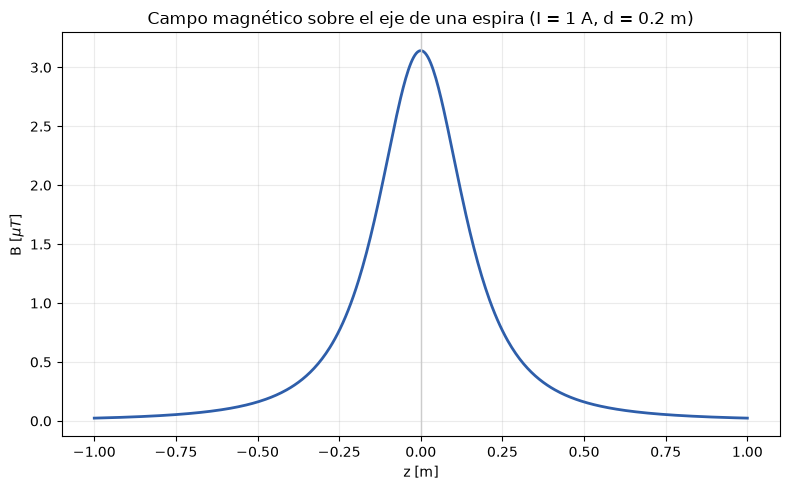

B en el centro (z=0) = 3.142 uT


In [1]:
import numpy as np
import matplotlib.pyplot as plt

mu0 = 4 * np.pi * 1e-7   # permeabilidad del vacío [T.m/A]

I = 1      # corriente [A]
d = 0.2    # radio de la espira [m]

z = np.linspace(-5 * d, 5 * d, 500)                  # distancia a lo largo del eje [m]
B = (mu0 * I * d**2) / (2 * (z**2 + d**2)**1.5)       # campo sobre el eje [T]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(z, B * 1e6, color="#2E5EAA", linewidth=2)
ax.axvline(0, color="0.8", linewidth=1)
ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title(f"Campo magnético sobre el eje de una espira (I = {I} A, d = {d} m)")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

B_centro = mu0 * I / (2 * d)
print(f"B en el centro (z=0) = {B_centro*1e6:.3f} uT")

### Por qué la curva tiene forma de campana

El gráfico muestra cómo cambia $B$ a medida que el punto $P$ se aleja del centro de la espira, moviéndose sobre el eje. Es una campana por dos efectos que se combinan:

1. **La distancia a cada punto de la espira crece.** En el centro ($z=0$) cada elemento de la espira está a la distancia mínima posible, $r=d$. A medida que $z$ crece, esa distancia pasa a ser $r=\sqrt{z^2+d^2}$, siempre mayor que $d$. Como el campo cae con $1/r^2$, alejarse ya debilita el campo.
2. **La proyección sobre el eje empeora.** Como vimos, solo sobrevive la componente de cada $d\vec{B}$ a lo largo del eje (las componentes perpendiculares se cancelan por simetría). En el centro esa proyección es la más favorable; cuanto más lejos está $P$, más oblicuo queda el segmento que va del cable a $P$, y menos campo queda apuntando en la dirección del eje.

Los dos efectos combinados hacen que el campo caiga más rápido de lo que caería el de un cable infinito. Por eso la curva:

* tiene su **máximo en $z=0$** (con $I=1\,A$ y $d=0{,}2\,m$, $B=3{,}14\,\mu T$),
* es **simétrica**: no hay ninguna razón física para que el campo sea distinto a un lado o al otro de la espira,
* y **cae rápidamente a cero**: con $z=\pm 1\,m$ (cinco veces el radio) el campo ya es casi nulo.

Esa forma de campana es justamente lo que distingue a la espira del cable infinito: el cable nunca "se apaga" del todo (el campo decae como $1/r$, muy lentamente), mientras que la espira concentra su campo cerca del centro y lo pierde rápido apenas $P$ se aleja sobre el eje.

### Dos espiras: ¿qué pasa si las combinamos?

Ahora agregamos una segunda espira, igual a la primera (mismo radio $d$ y misma corriente $I$, circulando en el mismo sentido), coaxial con la primera y separada una distancia $l$. Conviene ubicar el origen $z=0$ en el punto medio entre las dos espiras, así cada una queda centrada en $z=\mp l/2$:

$$B_1(z) = \frac{\mu_0 I}{2}\,\frac{d^2}{\left(\left(z-\tfrac{l}{2}\right)^2+d^2\right)^{3/2}} \qquad B_2(z) = \frac{\mu_0 I}{2}\,\frac{d^2}{\left(\left(z+\tfrac{l}{2}\right)^2+d^2\right)^{3/2}}$$

(es la misma relación que habíamos visto con $z+l$, solo que acá el origen queda en el medio de las dos espiras en vez de en el centro de la primera, para que el gráfico quede simétrico.)

Por el principio de superposición, el campo total es la suma de los dos:

$$B_{total}(z) = B_1(z) + B_2(z)$$

Para que se note bien la interacción entre los dos campos (el "valle" entre los dos picos) elegimos una separación $l$ mayor que el radio $d$: con $d=0,2\,m$, usamos $l=2d=0,4\,m$. Si las espiras estuvieran mucho más juntas (l mucho menor que d) los dos picos se fundirían en uno solo; si estuvieran muchísimo más separadas, se verían como dos campanas independientes, casi sin interacción entre sí (de hecho, hay una separación particular, $l=d$, en la que el campo se vuelve casi plano en el medio — es la base de las bobinas de Helmholtz, pero no es el caso que graficamos acá).

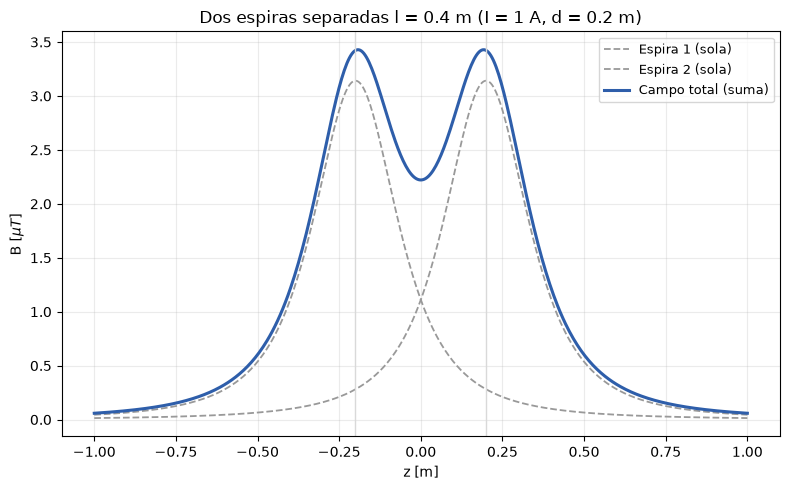

B en el centro de cada espira (z=+-l/2) = 3.423 uT
B en el punto medio (z=0)                = 2.221 uT


In [2]:
l = 2 * d   # separación entre las dos espiras [m]

def B_una_espira(z_rel):
    return (mu0 * I * d**2) / (2 * (z_rel**2 + d**2)**1.5)

z2 = np.linspace(-5 * d, 5 * d, 500)
B1 = B_una_espira(z2 - l / 2)
B2 = B_una_espira(z2 + l / 2)
B_total = B1 + B2

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(z2, B1 * 1e6, "--", color="0.6", linewidth=1.3, label="Espira 1 (sola)")
ax.plot(z2, B2 * 1e6, "--", color="0.6", linewidth=1.3, label="Espira 2 (sola)")
ax.plot(z2, B_total * 1e6, color="#2E5EAA", linewidth=2.2, label="Campo total (suma)")
ax.axvline(-l / 2, color="0.85", linewidth=1)
ax.axvline(l / 2, color="0.85", linewidth=1)
ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title(f"Dos espiras separadas l = {l} m (I = {I} A, d = {d} m)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"B en el centro de cada espira (z=+-l/2) = {B_una_espira(0)*1e6 + B_una_espira(l)*1e6:.3f} uT")
print(f"B en el punto medio (z=0)                = {2*B_una_espira(l/2)*1e6:.3f} uT")

Se forma la "M" que mencionaban: dos picos, uno por cada espira (donde cada una domina por estar más cerca), y un valle en el medio, donde ambas están relativamente lejos y ninguna compensa del todo la caída de la otra. Es la misma superposición que usamos siempre con Biot-Savart, solo que ahora los dos aportes que se suman no son infinitesimales ($d\vec{B}$ de un elemento de corriente) sino los campos completos de dos espiras enteras — el principio es el mismo en las dos escalas.

### Variando la separación entre espiras

¿Para cualquier separación $l$ se forma la M? No. Graficamos varias relaciones $l/d$ juntas, manteniendo siempre $I=1\,A$ y $d=0,2\,m$, para ver cómo cambia la forma del campo total a medida que se separan las espiras:

* Con $l$ chico (espiras muy juntas) los dos picos individuales se solapan tanto que se funden en uno solo, en $z=0$: **no hay M**.
* Con $l=d$ exactamente, el campo en el centro queda lo más "plano" posible (es la condición de Helmholtz) — tampoco hay un valle todavía, es el punto justo donde está por aparecer.
* A partir de $l>d$ empieza a formarse el valle en el centro, cada vez más marcado cuanto mayor es $l$: **ahí sí hay M**.

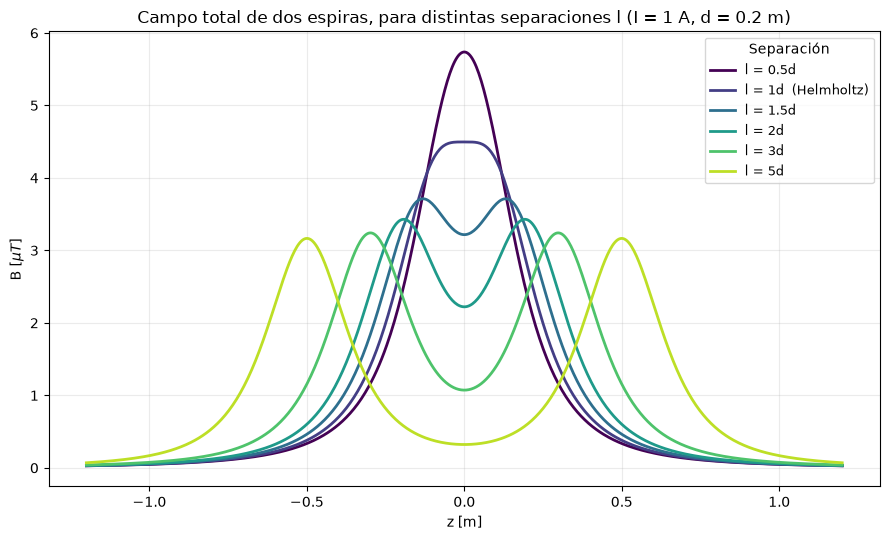

In [3]:
relaciones = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0]   # l/d a comparar
colores = plt.cm.viridis(np.linspace(0, 0.9, len(relaciones)))

z3 = np.linspace(-6 * d, 6 * d, 600)

fig, ax = plt.subplots(figsize=(9, 5.5))
for factor, color in zip(relaciones, colores):
    l_i = factor * d
    B_i = B_una_espira(z3 - l_i / 2) + B_una_espira(z3 + l_i / 2)
    etiqueta = f"l = {factor:g}d" + ("  (Helmholtz)" if factor == 1.0 else "")
    ax.plot(z3, B_i * 1e6, color=color, linewidth=2, label=etiqueta)

ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title(f"Campo total de dos espiras, para distintas separaciones l (I = {I} A, d = {d} m)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9, title="Separación")
fig.tight_layout()
plt.show()

Se ve la transición completa: con $l=0,5d$ y $l=d$ el campo tiene un único pico en el centro (sin valle); a partir de $l=1,5d$ ya aparece un mínimo local en $z=0$, que se hace cada vez más profundo (relativo a los picos) cuanto más se separan las espiras — hasta que para $l=5d$ casi se ven como dos campanas independientes, cada una pegada a su propia espira, con un valle bien marcado en el medio.

### Bobinas de Helmholtz

En muchos experimentos no alcanza con tener un campo magnético intenso en un único punto: hace falta una **zona** donde el campo sea lo más uniforme posible (constante), para que lo que se mida no dependa de la posición exacta del sensor. Dos espiras separadas la distancia justa logran eso en la región central — esa configuración se llama **bobinas de Helmholtz**.

**¿De dónde sale que esa distancia justa sea $l=d$?** Por la simetría de las dos espiras (misma corriente, mismo radio, una a cada lado del centro), la pendiente de $B_{total}(z)$ en $z=0$ ya es cero automáticamente: no importa $l$, ahí siempre hay un máximo o un mínimo local, nunca una pendiente distinta de cero. Esto se ve en todas las curvas del gráfico anterior — todas llegan "planas" (con derivada nula) a $z=0$, aunque unas sean picos y otras valles.

Lo que **no** es automático es que la curvatura también se anule ahí. Si tomamos la segunda derivada de $B_{total}(z)$ en $z=0$ e igualamos a cero (para que la curva no suba ni baje ni se curve, al menos cerca del centro), se llega a:

$$l = d$$

Es decir: **cuando la separación entre las espiras es igual al radio**, el campo en el centro no solo tiene pendiente nula (como en cualquier $l$), sino que además es lo más plano posible en un entorno del centro — ni pico ni valle, sino una meseta.

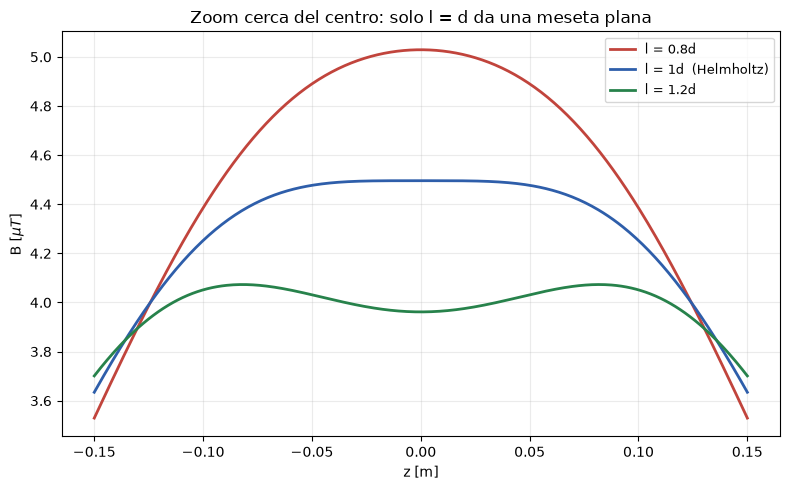

In [4]:
relaciones_h = [0.8, 1.0, 1.2]   # l/d cerca de la condición de Helmholtz
colores_h = ["#C1443C", "#2E5EAA", "#27824B"]

z4 = np.linspace(-0.15, 0.15, 400)

fig, ax = plt.subplots(figsize=(8, 5))
for factor, color in zip(relaciones_h, colores_h):
    l_i = factor * d
    B_i = B_una_espira(z4 - l_i / 2) + B_una_espira(z4 + l_i / 2)
    etiqueta = f"l = {factor:g}d" + ("  (Helmholtz)" if factor == 1.0 else "")
    ax.plot(z4, B_i * 1e6, color=color, linewidth=2, label=etiqueta)

ax.set_xlabel("z [m]")
ax.set_ylabel(r"B [$\mu T$]")
ax.set_title("Zoom cerca del centro: solo l = d da una meseta plana")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

Con el zoom cerca del centro se nota la diferencia: con $l=0,8d$ el campo ya viene cayendo desde $z=0$ (es un pico, no una meseta); con $l=1,2d$ pasa lo opuesto, el campo sube un poco antes de empezar a bajar (ya es parte de un valle, aunque todavía muy leve). Con $l=d$ exactamente, el campo se mantiene prácticamente constante en todo ese entorno — es la separación que usan en la práctica las bobinas de Helmholtz para generar una región de campo uniforme, útil por ejemplo para calibrar instrumentos o cancelar el campo magnético terrestre en una zona del laboratorio.

## 4. Procedimiento experimental

### Determinación del campo magnético terrestre

Para medir el campo magnético terrestre usamos una **brújula** ubicada en el centro de un par de **bobinas de Helmholtz**. Sin corriente, la aguja se alinea con la componente horizontal del campo terrestre, $\vec{B}_T$ (apunta al norte magnético). Si las bobinas se colocan con su eje horizontal y **perpendicular** a esa dirección (eje este-oeste), al hacer circular una corriente $I$ generan en el centro un campo $\vec{B}_H$ perpendicular a $\vec{B}_T$. La aguja se orienta según la **suma vectorial** de los dos campos, $\vec{B}_T + \vec{B}_H$, y se desvía un ángulo $\theta$ respecto del norte:

$$\tan\theta = \frac{B_H}{B_T}$$

Acá es donde sirve la configuración de Helmholtz ($l=d$): la brújula tiene un tamaño finito, y gracias a la meseta del campo en el centro toda la aguja ve el mismo $B_H$. Para dos bobinas de $N$ vueltas y radio $d$ separadas $l=d$, el campo en el centro es la suma de los aportes de las dos bobinas, cada una a una distancia $z=d/2$:

$$B_H = 2\cdot\frac{\mu_0 N I}{2}\,\frac{d^2}{\left(\left(\tfrac{d}{2}\right)^2+d^2\right)^{3/2}} = \left(\frac{4}{5}\right)^{3/2}\frac{\mu_0 N I}{d} = k\,I$$

donde $k = \left(\frac{4}{5}\right)^{3/2}\frac{\mu_0 N}{d}$ depende solo de las bobinas.

### Método de los 45°

Se aumenta la corriente hasta que la aguja queda a $\theta = 45°$. Como $\tan 45° = 1$, en ese punto los dos campos tienen el **mismo módulo**: la resultante es la diagonal de un cuadrado. Entonces, con $I_{45}$ la corriente a la que se llega a $45°$:

$$B_T = B_H = k\,I_{45} = \left(\frac{4}{5}\right)^{3/2}\frac{\mu_0 N\,I_{45}}{d}$$

Además, $45°$ es el ángulo en el que un error de lectura de la brújula afecta menos al resultado. El error relativo en $\tan\theta$ es $\dfrac{\sigma_{\tan\theta}}{\tan\theta} = \dfrac{\sigma_\theta}{\sin\theta\cos\theta}$, que es mínimo justamente en $\theta = 45°$ (donde vale $2\sigma_\theta$, con $\sigma_\theta$ en radianes).

**Importante:** la brújula solo puede girar en el plano horizontal, así que lo que se mide es la **componente horizontal** del campo terrestre, no su módulo total (que además tiene una componente vertical, según la inclinación magnética del lugar).

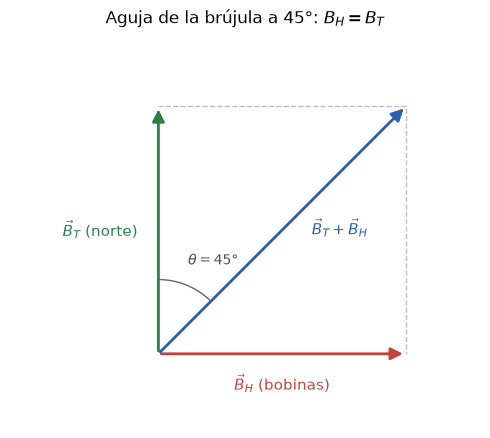

In [5]:
# Suma vectorial en el centro de las bobinas cuando la aguja marca 45° (B_H = B_T)
fig, ax = plt.subplots(figsize=(5, 5))
flecha = dict(arrowstyle="-|>", linewidth=2, mutation_scale=18)

ax.annotate("", xy=(0, 1), xytext=(0, 0), arrowprops=dict(flecha, color="#27824B"))
ax.annotate("", xy=(1, 0), xytext=(0, 0), arrowprops=dict(flecha, color="#C1443C"))
ax.annotate("", xy=(1, 1), xytext=(0, 0), arrowprops=dict(flecha, color="#2E5EAA"))
ax.plot([0, 1, 1], [1, 1, 0], "--", color="0.75", linewidth=1)

arco = np.linspace(np.pi / 4, np.pi / 2, 50)
ax.plot(0.3 * np.cos(arco), 0.3 * np.sin(arco), color="0.4", linewidth=1)

ax.text(-0.08, 0.5, r"$\vec{B}_T$ (norte)", color="#27824B", ha="right", va="center", fontsize=11)
ax.text(0.5, -0.08, r"$\vec{B}_H$ (bobinas)", color="#C1443C", ha="center", va="top", fontsize=11)
ax.text(0.62, 0.48, r"$\vec{B}_T + \vec{B}_H$", color="#2E5EAA", ha="left", fontsize=11)
ax.text(0.12, 0.36, r"$\theta = 45°$", color="0.3", fontsize=10)

ax.set_xlim(-0.6, 1.3)
ax.set_ylim(-0.3, 1.3)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Aguja de la brújula a 45°: $B_H = B_T$")
fig.tight_layout()
plt.show()

### Pasos

1. Alejar de la zona de medición objetos ferromagnéticos y cables con corriente (la fuente, celulares, patas o mesas metálicas), porque desvían la aguja.
2. Colocar la brújula en el centro de las bobinas, sin corriente, y esperar a que apunte al norte magnético. Girar el conjunto hasta que la aguja quede **paralela al plano de las bobinas** (es decir, perpendicular a su eje). Esa posición es $\theta = 0$. Conviene hacer esta alineación con cuidado: si el eje de las bobinas no queda exactamente en la dirección este-oeste, $\vec{B}_H$ no es perpendicular a $\vec{B}_T$ y la relación $\tan\theta = B_H/B_T$ deja de valer.
3. Conectar las dos bobinas **en serie** y de forma que la corriente circule en el mismo sentido en ambas (si no, los campos se restan y en el centro se anulan), junto con la fuente y un amperímetro.
4. Aumentar la corriente lentamente desde cero hasta que la aguja marque $45°$, y anotar la corriente $I_{45}$.

### Muestra teórica

Las bobinas usadas tienen $N = 200$ vueltas cada una y radio $d = 12\,cm$, y se ubican separadas $l = 12\,cm$, es decir en configuración de Helmholtz ($l = d$). Antes de medir, se calcula qué corriente esperar para llegar a $45°$, tomando como referencia una componente horizontal del campo terrestre de $\approx 18\,\mu T$ (valor aproximado para el Gran Buenos Aires).

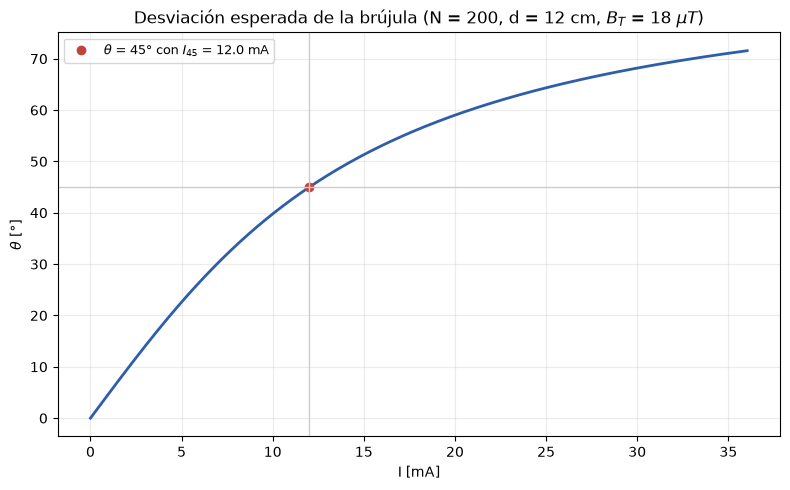

k = 1498.6 uT/A
Corriente esperada para theta = 45°: 12.0 mA
Entre 44° y 46° la corriente va de 11.60 mA a 12.44 mA (~0.42 mA por grado)


In [6]:
# Bobinas de Helmholtz usadas: dos espiras de 200 vueltas, radio 12 cm, separadas 12 cm
N_bob = 200      # vueltas de cada bobina
d_bob = 0.12     # radio de las bobinas [m] (separadas l = d_bob = 12 cm)

B_T_ref = 18e-6  # componente horizontal del campo terrestre esperada [T] (aproximada)

k = (4 / 5)**1.5 * mu0 * N_bob / d_bob    # B_H = k * I  [T/A]
I_45 = B_T_ref / k                        # corriente con la que se espera theta = 45°

I_teo = np.linspace(0, 3 * I_45, 300)
theta_teo = np.degrees(np.arctan(k * I_teo / B_T_ref))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(I_teo * 1e3, theta_teo, color="#2E5EAA", linewidth=2)
ax.plot(I_45 * 1e3, 45, "o", color="#C1443C", label=fr"$\theta$ = 45° con $I_{{45}}$ = {I_45*1e3:.1f} mA")
ax.axhline(45, color="0.8", linewidth=1)
ax.axvline(I_45 * 1e3, color="0.8", linewidth=1)
ax.set_xlabel("I [mA]")
ax.set_ylabel(r"$\theta$ [°]")
ax.set_title(f"Desviación esperada de la brújula (N = {N_bob}, d = {d_bob*100:.0f} cm, $B_T$ = {B_T_ref*1e6:.0f} $\\mu T$)")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# Cuánto cambia la corriente por cada grado alrededor de 45° (sensibilidad del método)
I_44 = np.tan(np.radians(44)) * B_T_ref / k
I_46 = np.tan(np.radians(46)) * B_T_ref / k
print(f"k = {k*1e6:.1f} uT/A")
print(f"Corriente esperada para theta = 45°: {I_45*1e3:.1f} mA")
print(f"Entre 44° y 46° la corriente va de {I_44*1e3:.2f} mA a {I_46*1e3:.2f} mA "
      f"(~{(I_46 - I_44) / 2 * 1e3:.2f} mA por grado)")

## 5. Mediciones y resultados

### Campo magnético terrestre

La aguja de la brújula llegó a $45°$ con una corriente $I_{45} = 12,15\,mA$.

In [7]:
# Medición: corriente con la que la aguja llega a 45°
I_45_med = 12.15e-3       # [A]

sigma_I = 0.01e-3         # resolución del amperímetro [A] (lectura con 2 decimales en mA)
sigma_theta = 1           # error de lectura de la brújula [°]
sigma_d = 1e-3            # error en el radio de las bobinas [m]

# Valor de referencia: componente horizontal según el modelo WMM2025 (NOAA/BGS)
# en la UNSAM (34° 34' 4" S, 58° 31' 8" W) el 22/10/2026
B_T_wmm = 16.92e-6        # [T]

Se calcula $B_T = k\,I_{45}$. Para su error se suman en cuadratura los errores relativos de la corriente (resolución del amperímetro), de la lectura del ángulo (que a $45°$ aporta $2\sigma_\theta$) y del radio de las bobinas:

$$\frac{\sigma_{B_T}}{B_T} = \sqrt{\left(\frac{\sigma_{I}}{I_{45}}\right)^2 + \left(2\sigma_\theta\right)^2 + \left(\frac{\sigma_d}{d}\right)^2}$$

In [8]:
B_T = k * I_45_med

err_I = sigma_I / I_45_med
err_theta = 2 * np.radians(sigma_theta)
err_d = sigma_d / d_bob
error_rel = np.sqrt(err_I**2 + err_theta**2 + err_d**2)
sigma_B_T = B_T * error_rel

print(f"I_45 = ({I_45_med*1e3:.2f} +/- {sigma_I*1e3:.2f}) mA")
print(f"\nB_T medido (componente horizontal) = ({B_T*1e6:.1f} +/- {sigma_B_T*1e6:.1f}) uT  ({error_rel*100:.1f} %)")
print(f"B_T según el modelo WMM            = {B_T_wmm*1e6:.2f} uT")
print(f"Diferencia = {(B_T - B_T_wmm) / B_T_wmm * 100:+.1f} %  ({abs(B_T - B_T_wmm) / sigma_B_T:.1f} veces el error estimado)")
print("\nAporte de cada fuente al error relativo:")
print(f"  corriente        {err_I * 100:.2f} %")
print(f"  ángulo (±{sigma_theta}°)     {err_theta * 100:.2f} %")
print(f"  radio (±{sigma_d*1e3:.0f} mm)    {err_d * 100:.2f} %")

# Ángulo que habría que haber leído para obtener exactamente el valor del WMM con esta corriente
theta_wmm = np.degrees(np.arctan(k * I_45_med / B_T_wmm))
print(f"\nCon {I_45_med*1e3:.2f} mA, el WMM predice una desviación de {theta_wmm:.1f}° (en lugar de 45°)")

I_45 = (12.15 +/- 0.01) mA

B_T medido (componente horizontal) = (18.2 +/- 0.7) uT  (3.6 %)
B_T según el modelo WMM            = 16.92 uT
Diferencia = +7.6 %  (2.0 veces el error estimado)

Aporte de cada fuente al error relativo:
  corriente        0.08 %
  ángulo (±1°)     3.49 %
  radio (±1 mm)    0.83 %

Con 12.15 mA, el WMM predice una desviación de 47.1° (en lugar de 45°)


### Análisis

* La aguja llegó a $45°$ con $I_{45} = 12,15\,mA$, cerca de los $\approx 12,0\,mA$ que anticipaba la muestra teórica. Con $k = 1498,6\,\mu T/A$ resulta una componente horizontal del campo terrestre de $B_T = (18,2 \pm 0,7)\,\mu T$.
* Como valor de referencia se usó el **World Magnetic Model** (WMM2025), el modelo del campo magnético terrestre que publican la NOAA y el British Geological Survey, evaluado en la UNSAM ($34°\,34'\,4''\,S$, $58°\,31'\,8''\,W$) el 22/10/2026. Para ese lugar y fecha predice una componente horizontal de $16,92\,\mu T$ (y un campo total de $22,5\,\mu T$, con una inclinación de $-41°$). El valor medido es un $7,6\%$ mayor, una diferencia del orden del **doble del error estimado**: el resultado tiene el orden de magnitud correcto, pero la diferencia no se explica solo con los errores considerados.
* La fuente de error dominante es la **lectura del ángulo**: un grado de error en la brújula aporta $\approx 3,5\%$, contra $\approx 0,8\%$ del radio de las bobinas y menos de $0,1\%$ de la corriente. Para que la medición coincida con el WMM, con $12,15\,mA$ la aguja tendría que haber marcado $\approx 47°$ en lugar de $45°$, es decir unos $2°$ de diferencia, lo que es posible con una brújula de graduación gruesa o una aguja que oscila.
* Hay además efectos que el error calculado **no** incluye y que pueden explicar el resto de la diferencia:
  * **Perturbaciones locales:** el WMM describe el campo generado por el núcleo terrestre, pero dentro de un edificio la estructura de hierro, las mesas metálicas y los cables con corriente modifican el campo en el lugar de la medición en algunos $\mu T$.
  * **Alineación:** si el eje de las bobinas no quedó exactamente en la dirección este-oeste, $\vec{B}_H$ no es perpendicular a $\vec{B}_T$ y la relación $\tan\theta = B_H/B_T$ deja de valer.
  * **Datos de las bobinas:** se usaron los valores nominales ($N = 200$, $d = l = 12\,cm$). Una diferencia en el número real de vueltas o en la separación entre las bobinas cambia $k$ directamente.
* Para mejorar la medición convendría una brújula con mejor graduación (más que un amperímetro más preciso), alejar el montaje de objetos metálicos y repetir la medición varias veces para estimar la dispersión.

## 6. Conclusiones

A partir de la ley de Biot-Savart obtuvimos el campo magnético sobre el eje de una espira circular: es máximo en el centro ($B = \mu_0 I / 2d$) y decae rápidamente y de forma simétrica al alejarse, dando una curva en forma de campana. Al sumar dos espiras coaxiales (principio de superposición), la forma del campo total depende de la separación $l$ entre ellas: con las espiras muy juntas se forma un único pico, y con las espiras separadas aparecen dos picos con un valle en el medio (la "M"). Entre esos dos casos está la configuración de **Helmholtz**, $l = d$, en la que el campo queda prácticamente uniforme en la zona central.

Esa región de campo uniforme es la que aprovechamos en la parte experimental para medir el campo magnético terrestre. Con una brújula en el centro de dos bobinas de $N = 200$ vueltas y radio $d = 12\,cm$, separadas $l = 12\,cm$, aumentamos la corriente hasta que la aguja marcó $45°$: en ese punto el campo de las bobinas y la componente horizontal del campo terrestre tienen el mismo módulo. La aguja llegó a $45°$ con $I_{45} = 12,15\,mA$, de lo que resulta:

$$B_T = \left(\frac{4}{5}\right)^{3/2}\frac{\mu_0 N\,I_{45}}{d} = (18,2 \pm 0,7)\,\mu T$$

Comparado con el valor de referencia del modelo WMM2025 para la UNSAM en la fecha de la medición ($16,92\,\mu T$), el resultado es un $7,6\%$ mayor. Es un acuerdo aceptable para un método tan simple: se obtuvo el orden de magnitud correcto de un campo muy débil (del orden de las decenas de $\mu T$) usando solo una brújula, dos bobinas y un amperímetro. La diferencia, algo mayor que el error estimado, se explica principalmente por la lectura del ángulo en la brújula (con $12,15\,mA$, el modelo predice una desviación de $\approx 47°$ en lugar de $45°$) y por efectos que el modelo no incluye, como las perturbaciones del campo dentro del laboratorio (estructura metálica del edificio, mesas y cables cercanos), la alineación de las bobinas con la dirección este-oeste y la tolerancia de los valores nominales de las bobinas.

El análisis de errores mostró que la incertidumbre de la medición está dominada por la lectura del ángulo ($\approx 3,5\%$ por cada grado), mucho más que por la corriente ($< 0,1\%$) o el radio de las bobinas ($\approx 0,8\%$). Por eso, para mejorar el resultado conviene usar una brújula con mejor graduación, alejar el montaje de objetos metálicos, cuidar la alineación inicial y repetir la medición varias veces para estimar la dispersión.